In [1]:
from google.colab import files
import os

print("Please choose your kaggle.json file:")
files.upload()

# Set up the credentials
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download the Chest X-Ray dataset directly to Colab
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

# Unzip the images
!unzip -q chest-xray-pneumonia.zip
print("Dataset downloaded and unzipped successfully!")

Please choose your kaggle.json file:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [02:00<00:00, 20.4MB/s]

Dataset downloaded and unzipped successfully!


In [3]:
!pip install -q timm grad-cam

import os
import glob
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Verify that your GPU is recognized
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Using device: cuda


In [4]:
data = []
# Find all .jpeg files inside the extracted folder
for filepath in glob.glob("chest_xray/**/*.jpeg", recursive=True):
    filename = os.path.basename(filepath)
    if "NORMAL" in filepath:
        label_id = 0
        label_name = "Normal"
    elif "bacteria" in filename.lower():
        label_id = 1
        label_name = "Bacterial Pneumonia"
    elif "virus" in filename.lower():
        label_id = 2
        label_name = "Viral Pneumonia"
    else:
        continue
    data.append({"filepath": filepath, "label_id": label_id, "label_name": label_name})

df = pd.DataFrame(data)
print(f"Total images found: {len(df)}")
print("\nClass breakdown:")
print(df["label_name"].value_counts())

Total images found: 11712

Class breakdown:
label_name
Bacterial Pneumonia    5560
Normal                 3166
Viral Pneumonia        2986
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

# 80% train, 20% test (stratified so each set gets an equal proportion of classes)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["label_id"])
print(f"Training images: {len(train_df)}")
print(f"Testing images: {len(test_df)}")

# Preprocessing & augmentation pipeline
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class XRayDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["filepath"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, row["label_id"]

# DataLoaders feed images in batches of 32 to the GPU
train_loader = DataLoader(XRayDataset(train_df, train_transforms), batch_size=32, shuffle=True)
test_loader = DataLoader(XRayDataset(test_df, test_transforms), batch_size=32, shuffle=False)
print("DataLoaders ready!")

Training images: 9369
Testing images: 2343
DataLoaders ready!


In [6]:
# 1. Load pre-trained DenseNet-121 architecture
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)

# 2. Modify the classifier head for 3 classes
in_features = model.classifier.in_features
model.classifier = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(in_features, 3)
)

# 3. Move the model to the GPU
model = model.to(device)

# 4. Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

print("DenseNet-121 architecture loaded and configured for 3 classes!")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 176MB/s]


DenseNet-121 architecture loaded and configured for 3 classes!


In [7]:
epochs = 5

print("Starting training on GPU...")
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = (correct / total) * 100
    print(f"Epoch {epoch+1}/{epochs} -> Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

# Save trained weights
torch.save(model.state_dict(), "densenet_pneumonia.pth")
print("\nTraining complete! Weights saved to 'densenet_pneumonia.pth'")

Starting training on GPU...
Epoch 1/5 -> Loss: 0.4614 | Accuracy: 80.71%
Epoch 2/5 -> Loss: 0.3287 | Accuracy: 86.49%
Epoch 3/5 -> Loss: 0.2478 | Accuracy: 90.28%
Epoch 4/5 -> Loss: 0.1745 | Accuracy: 93.59%
Epoch 5/5 -> Loss: 0.1354 | Accuracy: 95.13%

Training complete! Weights saved to 'densenet_pneumonia.pth'


Evaluating on test data...

CLASSIFICATION REPORT
                     precision    recall  f1-score   support

             Normal       0.95      0.99      0.97       634
Bacterial Pneumonia       0.96      0.89      0.93      1112
    Viral Pneumonia       0.82      0.90      0.86       597

           accuracy                           0.92      2343
          macro avg       0.91      0.93      0.92      2343
       weighted avg       0.92      0.92      0.92      2343



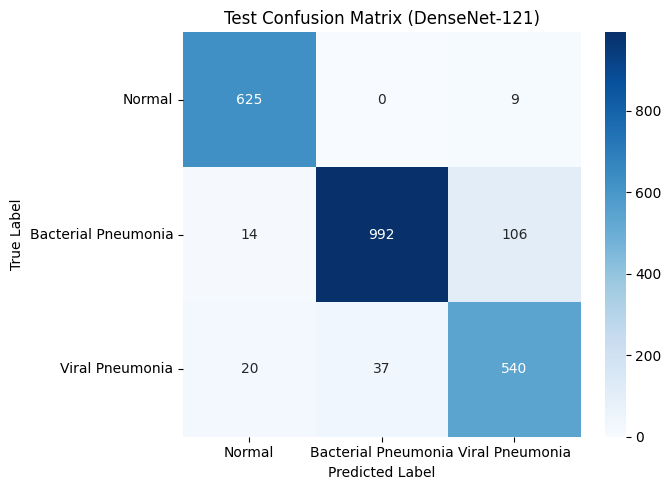

Confusion matrix saved as 'confusion_matrix.png'!


In [8]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()
all_preds = []
all_labels = []

print("Evaluating on test data...")
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

target_names = ["Normal", "Bacterial Pneumonia", "Viral Pneumonia"]

# Detailed precision, recall, and F1-score
print("\n" + "="*50)
print("CLASSIFICATION REPORT")
print("="*50)
print(classification_report(all_labels, all_preds, target_names=target_names))

# Confusion Matrix Heatmap
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Test Confusion Matrix (DenseNet-121)')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()
print("Confusion matrix saved as 'confusion_matrix.png'!")

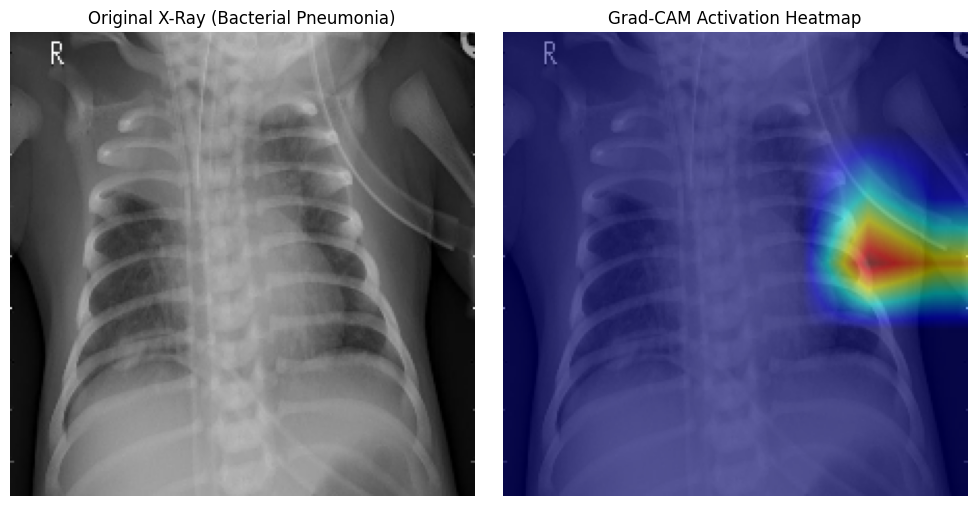

Grad-CAM visualization saved as 'gradcam_result.png'!


In [10]:
import cv2
import numpy as np
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# Select an image from the test set
sample_row = test_df[test_df["label_id"] == 1].iloc[0] # Picks a bacterial pneumonia sample
image_path = sample_row["filepath"]
actual_label = sample_row["label_name"]

# Load and prepare image
rgb_img = cv2.imread(image_path)
rgb_img = cv2.cvtColor(rgb_img, cv2.COLOR_BGR2RGB)
rgb_img = cv2.resize(rgb_img, (224, 224))
rgb_normalized = np.float32(rgb_img) / 255.0

input_tensor = test_transforms(Image.fromarray(rgb_img)).unsqueeze(0).to(device)

# Target the final convolutional layer of DenseNet-121
target_layers = [model.features.denseblock4.denselayer16.conv2]

cam = GradCAM(model=model, target_layers=target_layers)
# Fix: Pass targets=None to automatically target the highest scoring class
grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0]

# Overlay heatmap on original image
visualization = show_cam_on_image(rgb_normalized, grayscale_cam, use_rgb=True)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(rgb_img)
axes[0].set_title(f"Original X-Ray ({actual_label})")
axes[0].axis("off")

axes[1].imshow(visualization)
axes[1].set_title("Grad-CAM Activation Heatmap")
axes[1].axis("off")

plt.tight_layout()
plt.savefig("gradcam_result.png", dpi=300)
plt.show()
print("Grad-CAM visualization saved as 'gradcam_result.png'!")

In [11]:
import torch.nn as nn

# 1. Define a Baseline CNN from scratch
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(SimpleCNN, self).__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 112x112

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 56x56

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 28x28
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# 2. Instantiate and train baseline CNN
cnn_model = SimpleCNN(num_classes=3).to(device)
cnn_criterion = nn.CrossEntropyLoss()
cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

print("Training Custom Baseline CNN (from scratch)...")
epochs = 3 # 3 epochs is enough to show baseline performance

for epoch in range(epochs):
    cnn_model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        cnn_optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = cnn_criterion(outputs, labels)
        loss.backward()
        cnn_optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    print(f"CNN Epoch {epoch+1}/{epochs} -> Loss: {running_loss/total:.4f} | Accuracy: {(correct/total)*100:.2f}%")

print("Custom CNN baseline training complete!")

Training Custom Baseline CNN (from scratch)...
CNN Epoch 1/3 -> Loss: 1.2778 | Accuracy: 66.42%
CNN Epoch 2/3 -> Loss: 0.6543 | Accuracy: 68.48%
CNN Epoch 3/3 -> Loss: 0.6204 | Accuracy: 70.35%
Custom CNN baseline training complete!


In [12]:
cnn_model.eval()
cnn_correct, cnn_total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = cnn_model(images)
        _, preds = torch.max(outputs, 1)
        cnn_correct += (preds == labels).sum().item()
        cnn_total += labels.size(0)

cnn_test_acc = (cnn_correct / cnn_total) * 100
print(f"Custom CNN Test Accuracy: {cnn_test_acc:.2f}%")

Custom CNN Test Accuracy: 71.92%
